# 02. Clasificación con variables del pedido

Se evalúa si las variables operativas del pedido (entrega, productos, vendedores, pago y distancia) permiten identificar clientes insatisfechos con un F1 mayor a 0,7 en ambas clases. Se comparan Decision Tree, Random Forest, KNN, regresión logística y MLP.

In [1]:
import sys
sys.path.append("..")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier

from src.datos import cargar_pedidos, VARIABLES_PEDIDO
from src.modelos import (SEMILLA, comparar_modelos, buscar_hiperparametros, evaluar_finales,
                         submuestrear, recall_por_grupo)
from src.graficos import configurar_estilo, guardar, AZUL, NARANJA

configurar_estilo()
df = cargar_pedidos("../data/raw")

## 1. Partición y preprocesamiento

- Partición estratificada 80/20 en entrenamiento y prueba.
- Imputación de faltantes con la mediana del entrenamiento.
- Estandarización (`StandardScaler`) ajustada con el entrenamiento, necesaria para KNN, regresión logística y MLP.
- Submuestreo de la clase mayoritaria en el entrenamiento. Con 23 % de insatisfechos, un modelo que siempre predice "satisfecho" obtendría 77 % de exactitud y F1 = 0 en la clase de interés. El conjunto de prueba conserva la proporción original.

In [2]:
X = df[VARIABLES_PEDIDO]
y = df["insatisfecho"].values

X_ent, X_prueba, y_ent, y_prueba, grupo_ent, grupo_prueba = train_test_split(
    X, y, df["estado_entrega"].values, test_size=0.2, random_state=SEMILLA, stratify=y)

medianas = X_ent.median()
escalador = StandardScaler().fit(X_ent.fillna(medianas))
X_ent = escalador.transform(X_ent.fillna(medianas))
X_prueba = escalador.transform(X_prueba.fillna(medianas))

print(f"Entrenamiento: {len(y_ent):,} ({y_ent.mean():.1%} insatisfechos)")
print(f"Prueba: {len(y_prueba):,} ({y_prueba.mean():.1%} insatisfechos)")

Entrenamiento: 78,938 (22.9% insatisfechos)
Prueba: 19,735 (22.9% insatisfechos)


## 2. Modelos con parámetros por defecto

In [3]:
base, _ = comparar_modelos(X_ent, y_ent, X_prueba, y_prueba, balancear=True)
base

,f1_satisfecho,f1_insatisfecho
modelo,,
Decision Tree,0.692,0.409
Random Forest,0.832,0.498
KNN,0.760,0.447
Regresión logística,0.828,0.496
MLP,0.842,0.507


## 3. Búsqueda de hiperparámetros

Los valores se seleccionan con una partición de validación (20 % del entrenamiento), no con el conjunto de prueba, para que la evaluación final siga siendo sobre datos no vistos. El criterio es el mayor F1 mínimo entre las dos clases.

In [4]:
busqueda, mejores = buscar_hiperparametros(X_ent, y_ent, balancear=True)
busqueda.to_csv("../reports/busqueda_variables_pedido.csv", index=False)
busqueda.pivot_table(index=["modelo", "valor"], values=["f1_satisfecho", "f1_insatisfecho"], sort=False)

f1_satisfecho  f1_insatisfecho
modelo              valor                                    
Decision Tree       3                  0.871            0.496
                    5                  0.869            0.502
                    10                 0.849            0.489
                    20                 0.775            0.440
                    40                 0.700            0.411
                    None               0.691            0.407
Random Forest       10                 0.813            0.463
                    50                 0.826            0.486
                    100                0.832            0.492
                    200                0.833            0.493
KNN                 1                  0.704            0.417
                    3                  0.734            0.430
                    5                  0.756            0.442
                    11                 0.792            0.457
                    21                 0.817            0.469
                    51                 0.848            0.500
Regresión logística 0.01               0.826            0.486
                    0.1                0.826            0.486
                    1                  0.826            0.486
                    10                 0.826            0.486
MLP                 (10,)              0.842            0.501
                    (50,)              0.842            0.498
                    (100,)             0.842            0.498
                    (100, 50)          0.848            0.499

In [5]:
mejores

{'Decision Tree': 5,
 'Random Forest': 200,
 'KNN': 51,
 'Regresión logística': 0.1,
 'MLP': (10,)}

## 4. Evaluación en el conjunto de prueba

In [6]:
finales, matrices, modelos = evaluar_finales(mejores, X_ent, y_ent, X_prueba, y_prueba, balancear=True)
finales.to_csv("../reports/metricas_variables_pedido.csv")
finales

,hiperparametro,f1_satisfecho,f1_insatisfecho,supera_umbral
modelo,,,,
Decision Tree,max_depth=5,0.870,0.510,False
Random Forest,n_estimators=200,0.832,0.496,False
KNN,n_neighbors=51,0.845,0.504,False
Regresión logística,C=0.1,0.829,0.495,False
MLP,"hidden_layer_sizes=(10,)",0.830,0.499,False


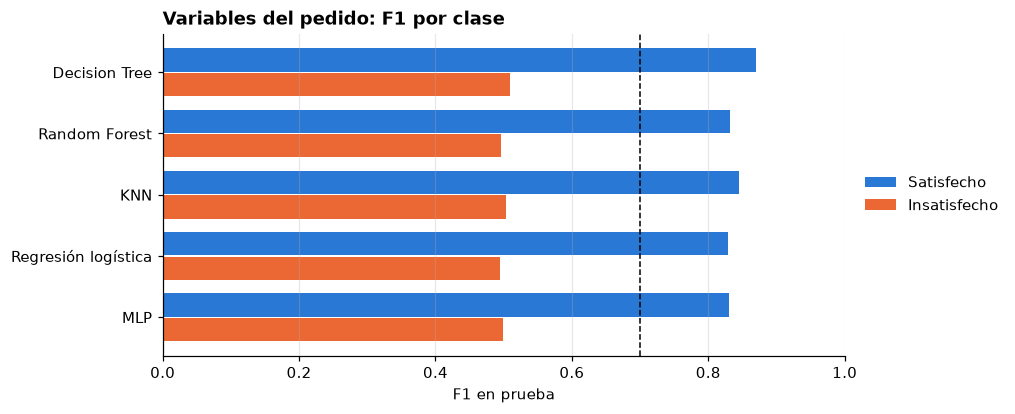

In [7]:
fig, ax = plt.subplots(figsize=(8, 3.8))
pos = np.arange(len(finales))
ax.barh(pos - 0.2, finales["f1_satisfecho"], height=0.38, color=AZUL, label="Satisfecho")
ax.barh(pos + 0.2, finales["f1_insatisfecho"], height=0.38, color=NARANJA, label="Insatisfecho")
ax.axvline(0.7, color="black", ls="--", lw=1)
ax.set_yticks(pos, finales.index)
ax.invert_yaxis()
ax.set_xlim(0, 1)
ax.set_xlabel("F1 en prueba")
ax.set_title("Variables del pedido: F1 por clase")
ax.grid(axis="x", alpha=0.3); ax.grid(axis="y", visible=False)
ax.legend(frameon=False, loc="center left", bbox_to_anchor=(1.01, 0.5))
guardar(fig, "f1_variables_pedido")
plt.show()

Ningún modelo supera el umbral en la clase insatisfecho. El Decision Tree sin límite de profundidad obtiene el peor resultado en validación, lo que indica sobreajuste; con `max_depth=5` mejora, pero no lo suficiente.

## 5. Análisis del error

Para comprobar la hipótesis del cuaderno 01 se calcula el *recall* de la clase insatisfecho según cómo se entregó el pedido, con el modelo de mejor F1 mínimo.

In [8]:
mejor = finales[["f1_satisfecho", "f1_insatisfecho"]].min(axis=1).idxmax()
print("Mejor modelo:", mejor, finales.loc[mejor, "hiperparametro"])
pred = modelos[mejor].predict(X_prueba)
recall_pedido = recall_por_grupo(y_prueba, pred, grupo_prueba)
recall_pedido.to_csv("../reports/recall_estado_entrega_pedido.csv")
recall_pedido

Mejor modelo: Decision Tree max_depth=5


,insatisfechos,detectados,recall
grupo,,,
A tiempo,3003,663,0.221
No entregado,536,532,0.993
Tarde,986,920,0.933


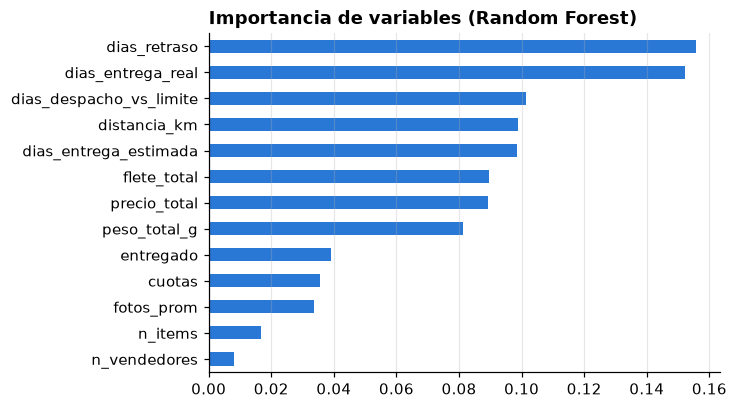

In [9]:
X_bal, y_bal = submuestrear(X_ent, y_ent)
rf = RandomForestClassifier(random_state=SEMILLA, n_jobs=-1).fit(X_bal, y_bal)
importancia = pd.Series(rf.feature_importances_, index=VARIABLES_PEDIDO).sort_values()

fig, ax = plt.subplots(figsize=(6, 4))
importancia.plot.barh(ax=ax, color=AZUL)
ax.set_title("Importancia de variables (Random Forest)")
ax.grid(axis="x", alpha=0.3); ax.grid(axis="y", visible=False)
plt.show()

## 6. Conclusión

Con variables del pedido el mejor resultado es un F1 de alrededor de 0,5 para la clase insatisfecho, por debajo del umbral de 0,7. El análisis del error confirma la hipótesis: el modelo detecta la mayoría de los insatisfechos cuyo pedido llegó tarde o no llegó, pero solo una fracción menor de los que lo recibieron a tiempo, que son dos tercios del total. Las variables más importantes son las de entrega.

La limitación no está en los algoritmos ni en sus hiperparámetros sino en la información disponible: para los pedidos entregados a tiempo, las variables no distinguen a un cliente satisfecho de uno insatisfecho. Como la causa de esas quejas aparece en los comentarios (cuaderno 01, sección 4.4) y el 63,5 % de los insatisfechos deja uno, el siguiente enfoque usa el texto de la reseña como variable explicativa.